#Product Review Sentiment Analyser
Group 6 - E-commerce

An app that understands how Nigerians write product reviews (including Pidgin) and shows sellers what customers are unhappy about.


###How the App Will Be Used
1. Sellers (main users): They will upload a file of their reviews or customer comments (from Jumia, Konga, Instagram, WhatsApp, etc.) and see how many are positive, negative or neutral, plus their most common complaints (e.g. delivery, fake products, battery etc.).
2. Shoppers: They will paste a single review, for example one in Pidgin, to quickly see if it is positive, negative or neutral.

Why didn't we just use star ratings? This is because ratings only show a score and not the reason behind it. Many Nigerian sellers (e.g. on Instagram and WhatsApp) receive only text comments with no ratings at all and a high rating can still hide a complaint in the text.


###Import Libraries

In [1]:
# Importing the libraries we need for this project
import pandas as pd                  # For loading and working with our data in table form
import numpy as np                   # For numerical operations
import matplotlib.pyplot as plt      # For creating charts and graphs
import seaborn as sns                # For creating cleaner and more detailed charts
import re                            # Python's built in library for cleaning text (e.g. removing links, emojis and symbols)


## Load and Inspect the Data
1. Dataset 1: Jumia Nigeria customer reviews (2021-2022)
2. Dataset 2: Nigerian Pidgin texts from the AfriSenti research project
3. Dataset 3: Nigerian app reviews of Jumia and Jiji, collected from Google Play


Data sources:
1. Dataset 1: Jumia Nigeria product reviews from a public GitHub project (Yungnas18/jumia-sentiment). We labelled them from their star ratings: 4-5 = positive, 3 = neutral, 1-2 = negative.
2. Dataset 2: Nigerian Pidgin texts from AfriSenti (Muhammad et al., 2023), a research dataset of African-language tweets labelled by native speakers.
3. Dataset 3: Public Google Play reviews of the Jumia and Jiji apps, collected on 20 November 2026 (process in our [Data_Collection notebook](https://colab.research.google.com/drive/1qLEyaNr9XUGAeVK1tw9Z7Xb9UjL_Dlsl?usp=sharing)) and labelled from their star ratings in the same way.



In [2]:
# Our three datasets are stored in Google Drive and shared as "Anyone with the link can view".
# This means every group member can load them directly, without uploading any files.

# Links to the three datasets (each link points to the file's ID in Google Drive)
jumia_url = "https://drive.google.com/uc?id=11RjHwjloKPd8H4rzMBW0bGnygmMWO928"
pidgin_url = "https://drive.google.com/uc?id=1KQvsxcV3dnYcrVzapG8532p_IFjTtFYr"
app_url = "https://drive.google.com/uc?id=1-XYnNPP7ftxheCk1NK5Xp39zPxlnEgj9"

# Let's read in the three datasets
jumia = pd.read_csv(jumia_url)        # Real customer reviews from Jumia Nigeria
pidgin = pd.read_csv(pidgin_url)      # Nigerian Pidgin texts labelled by sentiment
app_reviews = pd.read_csv(app_url)    # Nigerian app reviews of Jumia and Jiji from Google Play

# Let's check the shape of the three datasets (number of rows, number of columns)
print("Jumia shape:", jumia.shape)
print("Pidgin shape:", pidgin.shape)
print("App reviews shape:", app_reviews.shape)


Jumia shape: (2017, 5)
Pidgin shape: (10556, 3)
App reviews shape: (2633, 4)


###Dataset 1: Jumia Nigeria reviews


In [3]:
# Lets view the first 5 rows to see what the data looks like
jumia.head()


,Review Topic,Review Body,Rating(of 5),Review date,sentiment
0,I like it,It develops some little technical issues over ...,4,28-12-2022,positive
1,Earbud,The beat is awesome,5,28-12-2022,positive
2,Awesome stuff,Been using for over two months now. And it's b...,5,27-12-2022,positive
3,oraimo freepods-3 2baba earpod,The sound is cool,5,27-12-2022,positive
4,I love it.,It is a really good product. Great value for m...,5,23-12-2022,positive


In [4]:
# Lets get basic information about the dataset: column names, data types and non-null counts
jumia.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2017 entries, 0 to 2016
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Review Topic  2017 non-null   object
 1   Review Body   2017 non-null   object
 2   Rating(of 5)  2017 non-null   int64 
 3   Review date   2017 non-null   object
 4   sentiment     2017 non-null   object
dtypes: int64(1), object(4)
memory usage: 78.9+ KB


In [5]:
# lets check for missing values in each column
jumia.isnull().sum()


,0
Review Topic,0
Review Body,0
Rating(of 5),0
Review date,0
sentiment,0


In [6]:
# lets check the distribution of our target variable (sentiment)
# This shows how many reviews are positive, neutral and negative
jumia["sentiment"].value_counts()


,count
sentiment,
positive,1859
neutral,98
negative,60


In [7]:
# lets check for duplicate reviews (the same review text appearing more than once)
print("Number of duplicate reviews:", jumia.duplicated(subset=["Review Body"]).sum())


Number of duplicate reviews: 206


###Dataset 2: Nigerian pidgin texts


In [8]:
# Let's view the first 5 rows to see what the data looks like
pidgin.head()


,text,sentiment,split
0,yeah ‍️the guy wants to trend dat was why e jo...,negative,train
1,this life is so funny sef you will work hard a...,negative,train
2,dis is unfair of urcompany goingtowks nw ive b...,negative,train
3,lil wayne don vex me im actually not excited a...,negative,train
4,dis is unfair of ur company going to wks nw iv...,negative,train


In [9]:
# Let's get basic information about the dataset: column names, data types and non-null counts
pidgin.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10556 entries, 0 to 10555
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   text       10556 non-null  object
 1   sentiment  10556 non-null  object
 2   split      10556 non-null  object
dtypes: object(3)
memory usage: 247.5+ KB


In [10]:
# Let's check for missing values in each column
pidgin.isnull().sum()


,0
text,0
sentiment,0
split,0


In [11]:
# Let's check the distribution of our target variable (sentiment)
# This shows how many texts are positive, neutral and negative
pidgin["sentiment"].value_counts()


,count
sentiment,
negative,6380
positive,3652
neutral,524


In [12]:
# Let's check for duplicate texts (the same text appearing more than once)
print("Number of duplicate texts:", pidgin.duplicated(subset=["text"]).sum())


Number of duplicate texts: 1925


###Dataset 3: Nigerian App Reviews
Public Google Play reviews of Nigerian shopping apps (Jumia and Jiji), labelled from their star ratings
(1-2 = negative, 3 = neutral, 4-5 = positive). Added to give the model more real Nigerian complaint examples.


In [13]:
# Let's view the first 5 rows to see what the data looks like
app_reviews.head()


,text,rating,sentiment,source
0,app isn't working and it's not installing,1,negative,jumia_app
1,it's difficult to log in ur account,1,negative,jumia_app
2,"Hello Jumia, you put my order as ""Return in Pr...",1,negative,jumia_app
3,poor customer care poor refund people can't re...,1,negative,jumia_app
4,I requsted for return but I havn't recieve my ...,1,negative,jumia_app


In [14]:
# Let's get basic information about the dataset: column names, data types and non-null counts
app_reviews.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2633 entries, 0 to 2632
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   text       2633 non-null   object
 1   rating     2633 non-null   int64 
 2   sentiment  2633 non-null   object
 3   source     2633 non-null   object
dtypes: int64(1), object(3)
memory usage: 82.4+ KB


In [15]:
# Let's check for missing values in each column
app_reviews.isnull().sum()


,0
text,0
rating,0
sentiment,0
source,0


In [16]:
# Let's check the distribution of our target variable (sentiment)
app_reviews["sentiment"].value_counts()


,count
sentiment,
negative,1214
positive,929
neutral,490


In [17]:
# Let's check for duplicate reviews (the same review text appearing more than once)
print("Number of duplicate reviews:", app_reviews.duplicated(subset=["text"]).sum())


Number of duplicate reviews: 74


###Key Findings from Data Inspection

1. None of the datasets have missing values
2. All datasets contain some duplicate texts that need to be removed
3. The Jumia data is mostly positive, while the Pidgin data is mostly negative and the app reviews have more negative than positive reviews. So combining them will help balance the classes
4. The app reviews add over 1,200 real Nigerian complaints about shopping (delivery, refunds, orders)
5. Neutral is the smallest class in every dataset, which we will keep in mind during model evaluation


###Exploratory Data Analysis


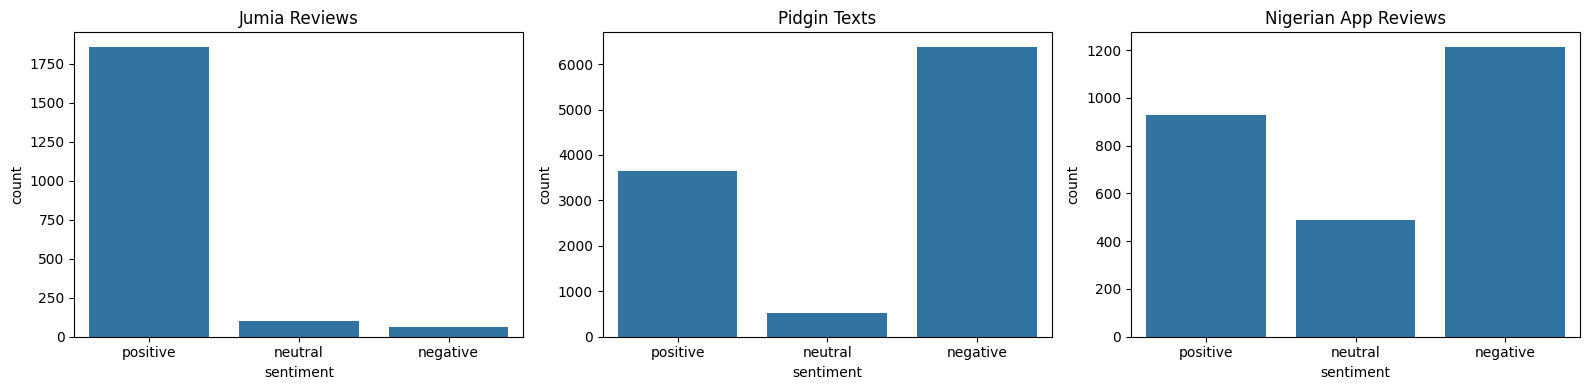

In [18]:
# Let's visualize the sentiment distribution of the three datasets side by side
fig, axes = plt.subplots(1, 3, figsize=(16, 4))      # This will create 3 charts next to each other
order = ["positive", "neutral", "negative"]

# Chart 1: Jumia reviews
sns.countplot(x="sentiment", data=jumia, order=order, ax=axes[0])
axes[0].set_title("Jumia Reviews")

# Chart 2: Pidgin texts
sns.countplot(x="sentiment", data=pidgin, order=order, ax=axes[1])
axes[1].set_title("Pidgin Texts")

# Chart 3: Nigerian app reviews
sns.countplot(x="sentiment", data=app_reviews, order=order, ax=axes[2])
axes[2].set_title("Nigerian App Reviews")

plt.tight_layout()     # This will adjust spacing so the charts don't overlap
plt.show()



In [19]:
# Let's see some sample reviews from each sentiment in the Jumia data
# This will help us understand what positive, neutral and negative reviews look like
for label in ["positive", "neutral", "negative"]:
    print("~" * 40)
    print(f" Sample {label} reviews:")
    print("~" * 40)
    print(jumia[jumia["sentiment"] == label]["Review Body"].head(3).tolist())   # Show the first 3 reviews of each type
    print()


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
 Sample positive reviews:
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
['It develops some little technical issues over time but it is still good btw.', 'The beat is awesome', "Been using for over two months now. And it's been awesome. The bass is a dream! The controls have a bit of issue cos I can't get the hang of it but it's easily negligible."]

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
 Sample neutral reviews:
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
['Mic call quality is poor', "The sound quality and bass is good. It has many issues with calls. Overall, it is very average and doesn't worth the hype", "I have issue with the voice, people can't hear me well especially on watsapp calls"]

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
 Sample negative reviews:
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
['It does not inform me when the battery is low. Sometimes the right ear does not come on and I have no idea why. \nOverall, I do not recommend it.', 'I’m d

In [20]:
# Let's do the same for the Pidgin data
for label in ["positive", "neutral", "negative"]:
    print("~" * 40)
    print(f" Sample {label} texts:")
    print("~" * 40)
    print(pidgin[pidgin["sentiment"] == label]["text"].head(3).tolist())        # Show the first 3 texts of each type
    print()


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
 Sample positive texts:
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
['please ooo i am not hurt i am just reacting to a tweet i saw about soft men even saw people who have dished pain to the softest men i know waggling their tail there na wetin vex me i am good my women dey try ️', 'baba na who dem give dey give thanks i don drop details tire make i smile like others na', 'e be like oooo baba just sabi too read wetin go commot and when e go read wetin no go commot too in go calm down jot am too']

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
 Sample neutral texts:
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
['david tar who be dat no be me dey pay am wetin you dey talk sef na me dey pay am so therefore what is his is mine joab big bros i no go advice you make you near there leave mata for matthias you know as e dey be david you wan die', 'my fellow e be like say na so so battle we go dey fight till this season finish', 'really would love to get sister locs 

In [21]:
# Let's do the same for the Nigerian app reviews
for label in ["positive", "neutral", "negative"]:
    print("~" * 40)
    print(f" Sample {label} app reviews:")
    print("~" * 40)
    print(app_reviews[app_reviews["sentiment"] == label]["text"].head(3).tolist())   # Show the first 3 reviews of each type
    print()


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
 Sample positive app reviews:
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
['Fast in delivering goods', 'Nice shopping with Jumia', 'it offers best and reliable products']

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
 Sample neutral app reviews:
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
['goods are being delivered', 'Good app but can you remove those pop up ads that pop up when searching for something else.', 'good so far']

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
 Sample negative app reviews:
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
["app isn't working and it's not installing", "it's difficult to log in ur account", 'Hello Jumia, you put my order as "Return in Progress" but that is WRONG. I NEVER received the item. I have nothing to return. Please CANCEL the return item and refund back to my opay refund now refund now refund now refund now refund now refund now refund now refund now refund now refund now refund now refund now refund now refund now ref

###Data Preparation

All three datasets need the same columns before we can combine them:
1. "text": the review text (our feature)
2. "sentiment": positive, negative or neutral (our target)
3. "source": where the row came from (jumia, pidgin, jumia_app or jiji_app), so we can evaluate on product reviews separately

The Pidgin data is not product reviews. It is used to teach the model how Nigerians express feelings in Pidgin and slang, and to add more negative examples.


In [22]:
# Let's make a fresh copy of the Jumia data so the original stays untouched
jumia_copy = jumia.copy()

# For Jumia, we will combine the Review Topic and Review Body into one text column,
# because the topic often sums up the customer's feeling (e.g. "I love it")
jumia_copy["text"] = jumia_copy["Review Topic"] + ". " + jumia_copy["Review Body"]

# We keep only the columns we need and add a column showing where the data came from
jumia_copy = jumia_copy[["text", "sentiment"]]
jumia_copy["source"] = "jumia"

jumia_copy.head()



,text,sentiment,source
0,I like it. It develops some little technical i...,positive,jumia
1,Earbud. The beat is awesome,positive,jumia
2,Awesome stuff. Been using for over two months ...,positive,jumia
3,oraimo freepods-3 2baba earpod. The sound is cool,positive,jumia
4,I love it.. It is a really good product. Great...,positive,jumia


Why we dropped Rating and Review date:
1. Rating was used to create our sentiment labels for the Jumia reviews and app reviews (4-5 = positive, 3 = neutral, 1-2 = negative). Keeping it as a feature would give the model the answer directly, which is data leakage. Also, app users only enter review text, not a rating.
2. Review date has no relationship with how a customer feels and the other datasets have no dates.


In [23]:
# For Pidgin, the text column already exists, so we make a fresh copy with only the columns we need
pidgin_copy = pidgin[["text", "sentiment"]].copy()

# Let's add a column showing where the data came from
pidgin_copy["source"] = "pidgin"

pidgin_copy.head()


,text,sentiment,source
0,yeah ‍️the guy wants to trend dat was why e jo...,negative,pidgin
1,this life is so funny sef you will work hard a...,negative,pidgin
2,dis is unfair of urcompany goingtowks nw ive b...,negative,pidgin
3,lil wayne don vex me im actually not excited a...,negative,pidgin
4,dis is unfair of ur company going to wks nw iv...,negative,pidgin


In [24]:
# For the app reviews, we make a fresh copy with only the columns we need
# (the source column already shows which app each review came from: jumia_app or jiji_app)
app_copy = app_reviews[["text", "sentiment", "source"]].copy()

app_copy.head()


,text,sentiment,source
0,app isn't working and it's not installing,negative,jumia_app
1,it's difficult to log in ur account,negative,jumia_app
2,"Hello Jumia, you put my order as ""Return in Pr...",negative,jumia_app
3,poor customer care poor refund people can't re...,negative,jumia_app
4,I requsted for return but I havn't recieve my ...,negative,jumia_app


In [25]:
# Let's combine the three datasets into one by stacking them on top of each other
# ignore_index=True gives the combined data a fresh row numbering (0, 1, 2,..)
df = pd.concat([jumia_copy, pidgin_copy, app_copy], ignore_index=True)

# Let's check the dimension of the combined data
print("Shape of combined data:", df.shape)


Shape of combined data: (15206, 3)


In [26]:
# Now let's confirm how many rows came from each source
df["source"].value_counts()


,count
source,
pidgin,10556
jumia,2017
jiji_app,1432
jumia_app,1201


In [27]:
# Let's view a random sample of 10 rows to confirm all the datasets are mixed
df.sample(10, random_state=234)


,text,sentiment,source
7407,e suppose shoot seun,negative,pidgin
7479,see ehhhh from everything ive watched in bbn s...,negative,pidgin
14870,"It's a great app, and handles mediation very w...",positive,jiji_app
2879,poverty get levels o my peoplesome people don ...,negative,pidgin
8770,smh must u eat we bam i don chop tire lol i de...,positive,pidgin
6839,guy if na me im sha raising brim and stones in...,positive,pidgin
8881,lol na wetin him get e go use na,positive,pidgin
681,I like it. The bass sound is Good.,positive,jumia
9114,what better way to start a week our chops they...,positive,pidgin
3271,some people get time to they speak english sha...,negative,pidgin


###Cleaning the Text
Our text cleaning steps:
1. We convert everything to lowercase (so "Good" and "good" are treated the same)
2. Remove links and @user mentions
3. Replace line breaks with spaces
4. Remove emojis, symbols, punctuation and hidden characters (we keep only letters and numbers)
5. Remove extra spaces

Note: we do not remove Pidgin words like "dey", "na", "wahala" because they carry the feeling we want the model to learn.


In [28]:
def clean_text(text):
    """
    A function that cleans a single review text
    """
    # If the text is missing, return an empty string
    if pd.isna(text):
        return ""

    # lets convert to lowercase
    text = str(text).lower()

    # lets remove links (http..., www...) and @user mentions
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)

    # lets replace line breaks with a space
    text = text.replace("\n", " ")

    # we keep only letters, numbers and spaces (this removes emojis, symbols, punctuation and hidden characters)
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # we replace multiple spaces with a single space and remove spaces at the start and end
    text = re.sub(r"\s+", " ", text).strip()

    return text


In [29]:
# Let's test the function on a few examples before applying it to the whole data
examples = [
    "Na ORIGINAL o!!! e sweet me well well 😍😍",
    "This phone no dey hold charge at all...\nWaste of money 😡",
    "@user check www.jumia.com.ng, delivery late reach one week!",
]

for example in examples:
    print("Before:", example)
    print("After: ", clean_text(example))
    print()


Before: Na ORIGINAL o!!! e sweet me well well 😍😍
After:  na original o e sweet me well well

Before: This phone no dey hold charge at all...
Waste of money 😡
After:  this phone no dey hold charge at all waste of money

Before: @user check www.jumia.com.ng, delivery late reach one week!
After:  check delivery late reach one week



In [30]:
# Let's make a separate copy for cleaning, so the combined data (df) stays unchanged
df_clean = df.copy()

# Let's apply the clean_text function to every row and save the result in a new column
df_clean["clean_text"] = df_clean["text"].apply(clean_text)

# Let's compare the original and cleaned text side by side
df_clean[["text", "clean_text"]].head(10)



,text,clean_text
0,I like it. It develops some little technical i...,i like it it develops some little technical is...
1,Earbud. The beat is awesome,earbud the beat is awesome
2,Awesome stuff. Been using for over two months ...,awesome stuff been using for over two months n...
3,oraimo freepods-3 2baba earpod. The sound is cool,oraimo freepods 3 2baba earpod the sound is cool
4,I love it.. It is a really good product. Great...,i love it it is a really good product great va...
5,good. I really like it,good i really like it
6,I love 3. It is very good,i love 3 it is very good
7,The oriamo legacy. Quality delivered as usual....,the oriamo legacy quality delivered as usual t...
8,Sound. Works perfectly with no issues ????,sound works perfectly with no issues
9,Sounds great. Great sound. Battery lasts long....,sounds great great sound battery lasts long cl...


###Removing Empty Texts and Duplicates


In [31]:
# Some texts may become empty after cleaning (e.g. a review that was only emojis)
print("Empty texts:", (df_clean["clean_text"] == "").sum())

# Let's drop the empty texts, if any, and save the result under a new name
df_no_empty = df_clean[df_clean["clean_text"] != ""]


Empty texts: 0


In [32]:
# Let's check for duplicates after cleaning
# (cleaning can create new duplicates, e.g. "Good!" and "good" both become "good")
print("Duplicates:", df_no_empty.duplicated(subset=["clean_text"]).sum())

# Let's drop the duplicates, keeping only the first occurrence, and save the final data under a new name
df_final = df_no_empty.drop_duplicates(subset=["clean_text"], keep="first")

# Let's check the dimension of the final data
print("Shape after removing duplicates:", df_final.shape)


Duplicates: 2096
Shape after removing duplicates: (13110, 4)


###Final Check


In [33]:
# Let's check for missing values one last time
df_final.isnull().sum()



,0
text,0
sentiment,0
source,0
clean_text,0


In [34]:
# Let's see the final sentiment distribution and how many rows came from each source
print("~" * 40)
print(" Final sentiment distribution:")
print("~" * 40)
print(df_final["sentiment"].value_counts())
print()

print("~" * 40)
print(" Rows from each source:")
print("~" * 40)
print(df_final["source"].value_counts())


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
 Final sentiment distribution:
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
sentiment
negative    6478
positive    5554
neutral     1078
Name: count, dtype: int64

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
 Rows from each source:
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
source
pidgin       8630
jumia        1972
jiji_app     1350
jumia_app    1158
Name: count, dtype: int64


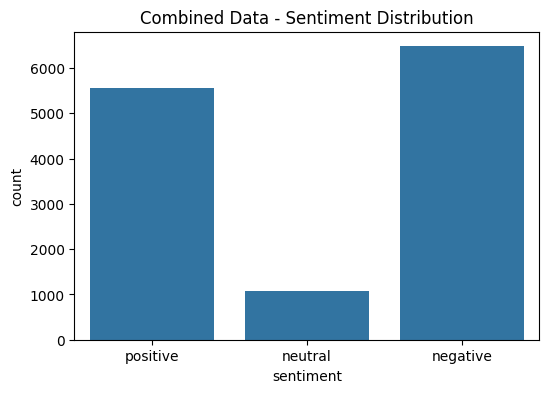

In [35]:
# Let's have a visual confirmation of the final sentiment distribution
plt.figure(figsize=(6, 4))
sns.countplot(x="sentiment", data=df_final, order=["positive", "neutral", "negative"])
plt.title("Combined Data - Sentiment Distribution")
plt.show()


###Summary of Data Cleaning
1. We combined 2,017 Jumia reviews, 10,556 Pidgin texts and 2,633 Nigerian app reviews into 15,206 rows
2. After cleaning and removing 2,096 duplicates, we have 13,110 clean rows
3. Final sentiment distribution: 6,478 negative, 5,554 positive and 1,078 neutral
4. Adding the Nigerian app reviews gave the model many more real complaint examples and the classes are now much more balanced
5. Neutral is still the smallest class, so in model evaluation we will use the F1 score and not just accuracy



##Model Training and Comparison
In this section we are going to:
1. Split the data into training and testing sets
2. Convert the text into numbers using TF-IDF
3. Train three models: Logistic Regression, Naive Bayes and XGBoost
4. Compare them using accuracy and F1 score, including on Jumia product reviews only


In [36]:
# Importing the libraries we need for model training and evaluation
from sklearn.model_selection import train_test_split            # For splitting the data into training and testing sets
from sklearn.feature_extraction.text import TfidfVectorizer     # For converting text into numbers
from sklearn.linear_model import LogisticRegression             # Model 1
from sklearn.naive_bayes import MultinomialNB                   # Model 2
from xgboost import XGBClassifier                               # Model 3
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix   # For evaluating the models


###Preparing the Labels
Models work with numbers, so we convert each sentiment into a number: negative = 0, neutral = 1, positive = 2.


In [37]:
# Let's make a copy of the final data for modelling, so df_final stays unchanged
df_model = df_final.copy()

# Let's convert each sentiment into a number, because models work with numbers
label_map = {"negative": 0, "neutral": 1, "positive": 2}
df_model["label"] = df_model["sentiment"].map(label_map)

# Let's confirm the conversion is correct
df_model[["sentiment", "label"]].value_counts()


,,count
sentiment,label,
negative,0,6478
positive,2,5554
neutral,1,1078


###Splitting the Data
We split the data into 80% for training and 20% for testing. The model learns from the training set, and we check how well it performs on the testing set, which it has never seen.

We use "stratify" so that both sets keep the same mix of positive, neutral and negative reviews.


In [38]:
# Let's split the data: 80% for training and 20% for testing
# stratify helps keep the same mix of positive, neutral and negative in both sets
# random_state makes the split the same every time we run it
train_df, test_df = train_test_split(df_model, test_size=0.2, stratify=df_model["label"], random_state=234)

# Our feature (X) is the cleaned text, and our target (y) is the label
X_train = train_df["clean_text"]
y_train = train_df["label"]
X_test = test_df["clean_text"]
y_test = test_df["label"]

# Let's check the size of each set
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)


Training set: (10488,)
Testing set: (2622,)


###Converting Text to Numbers (TF-IDF)
Models cannot read words, so we use TF-IDF to turn each review into numbers. It gives more weight to useful words (like "fake", "refund", "wahala") and less weight to very common words (like "the", "is").

We also include pairs of words (e.g. "no work", "not good"), because the meaning often comes from two words together.

Important: we fit TF-IDF on the training set only. If it also learned from the testing set, the test would no longer be fair (data leakage).


In [39]:
# Let's create the TF-IDF converter
# ngram_range=(1, 2) it uses single words and pairs of words (e.g. "no work", "not good")
# min_df=2 it ignores words that appear in fewer than 2 reviews (usually typos)
# sublinear_tf=True it stops very repeated words in one review from getting too much weight
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)

# Let's learn the vocabulary from the training set only, then convert it to numbers
X_train_tfidf = tfidf.fit_transform(X_train)

# Let's convert the testing set using the same vocabulary (transform only, no fitting)
X_test_tfidf = tfidf.transform(X_test)

# Let's check the result: (number of reviews, number of words and word pairs)
print("Training set after TF-IDF:", X_train_tfidf.shape)
print("Testing set after TF-IDF:", X_test_tfidf.shape)


Training set after TF-IDF: (10488, 25300)
Testing set after TF-IDF: (2622, 25300)


##Model 1: Logistic Regression
Logistic Regression gives each word a score that pushes a review towards positive, neutral or negative, then picks the label with the highest total. It is fast, simple and easy to explain.

We use class_weight="balanced" so the model pays more attention to neutral reviews, because they are the smallest class.


In [40]:
# Let's create the Logistic Regression model
# class_weight="balanced" makes the model pay more attention to the smaller classes (especially neutral)
# max_iter=1000 gives the model enough steps to finish learning
lr_model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=234)

# Let's train the model on the training set
lr_model.fit(X_train_tfidf, y_train)

# Let's make predictions on the testing set
lr_pred = lr_model.predict(X_test_tfidf)

print("Logistic Regression has been trained!")


Logistic Regression has been trained!


###Evaluating the Model
We check the model with:
1. Accuracy: the percentage of reviews it got right
2. F1 score (macro):the average F1 across positive, neutral and negative.This is our main score, because it treats the small neutral class as equally important
3. Classification report:precision, recall and F1 for each class
4. Confusion matrix:This shows which classes the model mixes up

We decided to put this in a function so we can evaluate all three models the same way.


In [41]:
# The class names in the same order as our labels (0, 1, 2)
class_names = ["negative", "neutral", "positive"]

def evaluate_model(model_name, y_true, y_pred):
    """
    A function that prints the accuracy, F1 score and classification report,
    and shows the confusion matrix for a model
    """
    # Let's calculate the accuracy and the macro F1 score
    accuracy = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average="macro")

    print("~" * 40)
    print(f" {model_name}")
    print("~" * 40)
    print(f"Accuracy: {accuracy:.3f}")
    print(f"F1 score (macro): {f1:.3f}")
    print()

    # Let's see the precision, recall and F1 for each class
    print(classification_report(y_true, y_pred, target_names=class_names))

    # Let's visualize the confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix - {model_name}")
    plt.show()

    # We return the scores so we can compare all the models later
    return accuracy, f1


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
 Logistic Regression
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Accuracy: 0.659
F1 score (macro): 0.550

              precision    recall  f1-score   support

    negative       0.70      0.78      0.74      1296
     neutral       0.22      0.31      0.26       215
    positive       0.75      0.58      0.66      1111

    accuracy                           0.66      2622
   macro avg       0.56      0.56      0.55      2622
weighted avg       0.68      0.66      0.66      2622



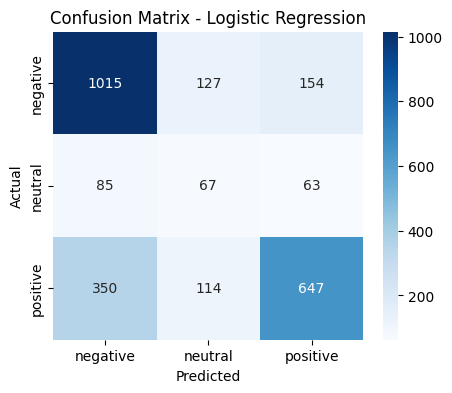

In [42]:
# Let's evaluate Logistic Regression on the whole testing set
lr_accuracy, lr_f1 = evaluate_model("Logistic Regression", y_test, lr_pred)


###Logistic Regression Results
1. Accuracy: 0.659, so the model got about 66% of the test reviews right
2. F1 score (macro): 0.550, which is our main score
3. Negative F1: 0.74: the model is good at spotting complaints, which matters most for sellers
4. Positive F1: 0.66: decent
5. Neutral F1: 0.26: weak, because neutral has the fewest examples and is naturally hard to tell apart
6. The biggest mistake (from the confusion matrix) is 350 positive reviews predicted as negative. Many of these come from the Pidgin tweets, which are less clear than product reviews


###Evaluating by Data Source
Our app is mainly for product reviews, so we also check how the model performs on each source separately: Jumia reviews, Jumia app reviews, Jiji app reviews and Pidgin texts.


In [43]:
def evaluate_by_source(model_name, y_pred):
    """
    A function that shows the accuracy and F1 score of a model for each data source
    """
    print("~" * 40)
    print(f" {model_name}: results by source")
    print("~" * 40)

    for source in ["jumia", "jumia_app", "jiji_app", "pidgin"]:
        # Let's select only the test reviews from this source
        mask = (test_df["source"] == source).values
        accuracy = accuracy_score(y_test[mask], y_pred[mask])
        f1 = f1_score(y_test[mask], y_pred[mask], average="macro")
        print(f"{source:<10} reviews: {mask.sum():<5} Accuracy: {accuracy:.3f}   F1 (macro): {f1:.3f}")

    # Let's also check all the product reviews together (Jumia + app reviews)
    product_mask = test_df["source"].isin(["jumia", "jumia_app", "jiji_app"]).values
    product_f1 = f1_score(y_test[product_mask], y_pred[product_mask], average="macro")
    print()
    print(f"All product reviews F1 (macro): {product_f1:.3f}")

    # Then we return the product reviews F1 so we can compare the models later
    return product_f1


In [44]:
# Let's see how Logistic Regression performs on each data source
lr_product_f1 = evaluate_by_source("Logistic Regression", lr_pred)

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
 Logistic Regression: results by source
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
jumia      reviews: 389   Accuracy: 0.895   F1 (macro): 0.552
jumia_app  reviews: 226   Accuracy: 0.531   F1 (macro): 0.514
jiji_app   reviews: 276   Accuracy: 0.540   F1 (macro): 0.491
pidgin     reviews: 1731  Accuracy: 0.642   F1 (macro): 0.471

All product reviews F1 (macro): 0.593


###Results by Source
1. On all product reviews (Jumia + app reviews), the F1 score is 0.593, higher than on the whole testing set (0.550). This is good, because product reviews are what our app is for
2. Jumia reviews have a high accuracy (0.895) but a lower F1 (0.552). Most Jumia reviews are positive, so accuracy looks high even though the model still struggles with the few complaints and neutral reviews. This is why we use F1
3. The app reviews are harder (F1 around 0.5), because they are short and some star ratings do not match the words


##Model 2: Naive Bayes
Naive Bayes learns how often each word appears in positive, neutral and negative reviews. For a new review, it calculates which label is most likely based on its words. It is also very fast and works well on short texts like reviews and tweets.

Naive Bayes does not have a class_weight option, so we give it sample weights instead. This makes the neutral reviews count more during training, just like we did for Logistic Regression.


In [45]:
from sklearn.utils.class_weight import compute_sample_weight   # this is to give the smaller classes more weight

# Let's give each training review a weight, so the smaller classes (especially neutral) count more
nb_weights = compute_sample_weight(class_weight="balanced", y=y_train)

# Let's create and train the Naive Bayes model
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train, sample_weight=nb_weights)

# Let's make predictions on the testing set
nb_pred = nb_model.predict(X_test_tfidf)

print("Naive Bayes has been trained!")


Naive Bayes has been trained!


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
 Naive Bayes
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Accuracy: 0.614
F1 score (macro): 0.517

              precision    recall  f1-score   support

    negative       0.65      0.81      0.72      1296
     neutral       0.20      0.40      0.26       215
    positive       0.83      0.43      0.57      1111

    accuracy                           0.61      2622
   macro avg       0.56      0.54      0.52      2622
weighted avg       0.69      0.61      0.62      2622



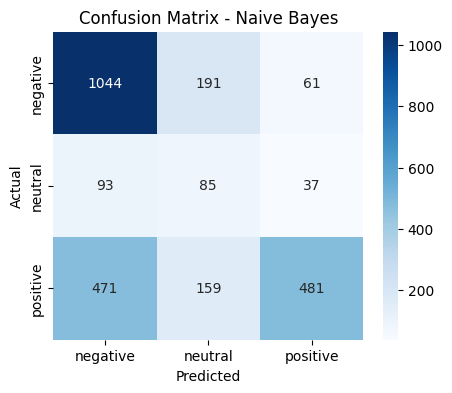

In [46]:
# Let's evaluate Naive Bayes on the whole testing set
nb_accuracy, nb_f1 = evaluate_model("Naive Bayes", y_test, nb_pred)


### Naive Bayes Results
1. Accuracy: 0.614 and F1 score (macro): 0.517, slightly lower than Logistic Regression (0.550)
2. Negative F1: 0.72: still good at spotting complaints
3. Neutral F1: 0.26: the same as Logistic Regression. It finds more neutral reviews, but it also wrongly labels many other reviews as neutral
4. Positive F1: 0.57: its main weakness. 471 positive reviews were predicted as negative, more than Logistic Regression's 350


In [47]:
# Let's see how Naive Bayes performs on each data source
nb_product_f1 = evaluate_by_source("Naive Bayes", nb_pred)


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
 Naive Bayes: results by source
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
jumia      reviews: 389   Accuracy: 0.902   F1 (macro): 0.461
jumia_app  reviews: 226   Accuracy: 0.389   F1 (macro): 0.398
jiji_app   reviews: 276   Accuracy: 0.337   F1 (macro): 0.342
pidgin     reviews: 1731  Accuracy: 0.623   F1 (macro): 0.378

All product reviews F1 (macro): 0.504


###Naive Bayes Results by Source
1. On all product reviews, the F1 score is 0.504, lower than Logistic Regression (0.593)
2. Naive Bayes is weaker than Logistic Regression on every source, especially on the app reviews (F1 of 0.398 for Jumia app and 0.342 for Jiji app)
3. So far, Logistic Regression is the better model


##Model 3: XGBoost
XGBoost builds many small decision trees, one after another. Each new tree focuses on fixing the mistakes of the trees before it. It is often very accurate and can learn combinations of words, but it is slower to train and harder to explain.

Like Naive Bayes, we give it sample weights so the neutral reviews count more during training.


In [48]:
# Let's give each training review a weight, so the smaller classes (especially neutral) count more
xgb_weights = compute_sample_weight(class_weight="balanced", y=y_train)

# Let's create the XGBoost model
# n_estimators=300 builds 300 small trees
# max_depth=6 limits how deep each tree can grow, so it doesn't memorise the training data
# learning_rate=0.1 controls how much each new tree corrects the previous ones
xgb_model = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                          eval_metric="mlogloss", random_state=234, n_jobs=-1)

# Let's train the model on the training set
xgb_model.fit(X_train_tfidf, y_train, sample_weight=xgb_weights)

# Let's make predictions on the testing set
xgb_pred = xgb_model.predict(X_test_tfidf)

print("XGBoost has been trained!")


XGBoost has been trained!


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
 XGBoost
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Accuracy: 0.622
F1 score (macro): 0.538

              precision    recall  f1-score   support

    negative       0.71      0.72      0.71      1296
     neutral       0.20      0.45      0.28       215
    positive       0.74      0.54      0.63      1111

    accuracy                           0.62      2622
   macro avg       0.55      0.57      0.54      2622
weighted avg       0.68      0.62      0.64      2622



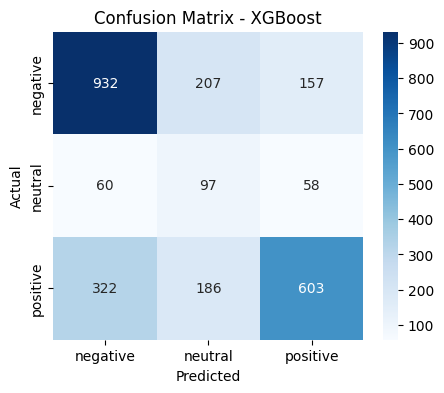

In [49]:
# Let's evaluate XGBoost on the whole testing set
xgb_accuracy, xgb_f1 = evaluate_model("XGBoost", y_test, xgb_pred)


###XGBoost Results
1. Accuracy: 0.622 and F1 score (macro): 0.538, between Logistic Regression (0.550) and Naive Bayes (0.517)
2. Negative F1: 0.71: good at spotting complaints, but it labels more complaints as neutral (207)
3. Neutral F1: 0.28: the best of the three models so far. It finds 45% of neutral reviews
4. Positive F1: 0.63 fewer positive reviews predicted as negative (322) than Logistic Regression (350)
5. XGBoost took about 2 minutes to train, compared with a few seconds for Logistic Regression


In [50]:
# Let's see how XGBoost performs on each data source
xgb_product_f1 = evaluate_by_source("XGBoost", xgb_pred)


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
 XGBoost: results by source
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
jumia      reviews: 389   Accuracy: 0.877   F1 (macro): 0.562
jumia_app  reviews: 226   Accuracy: 0.438   F1 (macro): 0.444
jiji_app   reviews: 276   Accuracy: 0.536   F1 (macro): 0.511
pidgin     reviews: 1731  Accuracy: 0.603   F1 (macro): 0.461

All product reviews F1 (macro): 0.578


###XGBoost Results by Source
1. On all product reviews, the F1 score is 0.578, slightly lower than Logistic Regression (0.593) but higher than Naive Bayes (0.504)
2. XGBoost is slightly better than Logistic Regression on Jumia reviews (0.562) and Jiji app reviews (0.511), but weaker on Jumia app reviews (0.444)


##Comparing the Three Models
We compare the models using the F1 score, our main measure, on the whole testing set and on product reviews only.


In [51]:
# Let's put the scores of the three models in one table
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Naive Bayes", "XGBoost"],
    "Accuracy": [lr_accuracy, nb_accuracy, xgb_accuracy],
    "F1 (all reviews)": [lr_f1, nb_f1, xgb_f1],
    "F1 (product reviews)": [lr_product_f1, nb_product_f1, xgb_product_f1],
})

# Let's sort the models from best to worst by F1 on product reviews, since that is what our app is for
comparison = comparison.sort_values("F1 (product reviews)", ascending=False).round(3)
comparison


,Model,Accuracy,F1 (all reviews),F1 (product reviews)
0,Logistic Regression,0.659,0.550,0.593
2,XGBoost,0.622,0.538,0.578
1,Naive Bayes,0.614,0.517,0.504


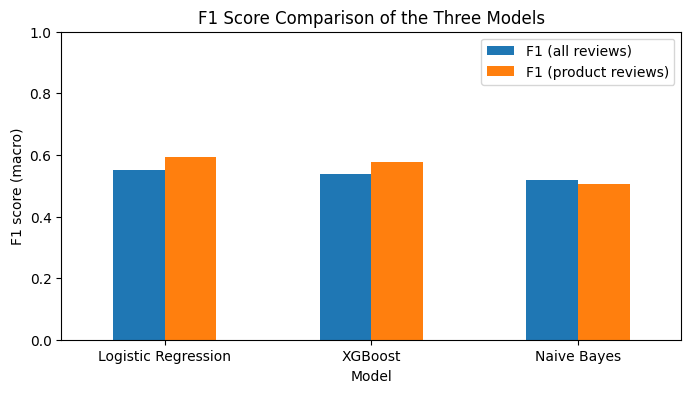

In [52]:
# Let's visualize the F1 scores of the three models side by side
comparison.set_index("Model")[["F1 (all reviews)", "F1 (product reviews)"]].plot(kind="bar", figsize=(8, 4))
plt.title("F1 Score Comparison of the Three Models")
plt.ylabel("F1 score (macro)")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.show()


###Which Model Did We Pick?
Logistic Regression performed best, so we choose it as our main model:
1. It has the highest F1 score on product reviews (0.593), which is what our app is mainly for
2. It also has the highest F1 on all reviews (0.550) and the highest accuracy (0.659)
3. It trains in a few seconds, while XGBoost takes about 2 minutes
4. It is easy to explain, because we can see which words push a review towards positive, neutral or negative

XGBoost came a close second (0.578 on product reviews) and was the best at finding neutral reviews, while Naive Bayes was the weakest (0.504).

In the improvement stage, we will try to make the best model even better and handle the neutral class.



##Comparing Our Model with TextBlob and VADER
TextBlob and VADER are two popular, ready made sentiment tools. They work with a fixed list of English words, where each word has a score (e.g. "good" = positive, "bad" = negative). Words that are not on their list, such as Pidgin words like "wahala" or "e no work" are ignored.

Our model learns from thousands of real Nigerian examples instead. Here we test whether that makes it better at understanding how Nigerians write.

To compare fairly, we turn each tool's score into the same three labels:
1. VADER: score of 0.05 or more = positive, -0.05 or less = negative, anything in between = neutral
2. TextBlob: score above 0 = positive, below 0 = negative, exactly 0 = neutral


In [53]:
# Let's install VADER and TextBlob, since they don't come with Colab by default
!pip install vaderSentiment textblob -q


In [54]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from textblob import TextBlob

# Let's create the VADER analyser
vader = SentimentIntensityAnalyzer()

def vader_label(text):
    """
    A function that turns VADER's score into our labels (0 = negative, 1 = neutral, 2 = positive)
    """
    score = vader.polarity_scores(str(text))["compound"]
    if score >= 0.05:
        return 2
    elif score <= -0.05:
        return 0
    else:
        return 1

def textblob_label(text):
    """
    A function that turns TextBlob's score into our labels (0 = negative, 1 = neutral, 2 = positive)
    """
    score = TextBlob(str(text)).sentiment.polarity
    if score > 0:
        return 2
    elif score < 0:
        return 0
    else:
        return 1


In [55]:
# Let's test all three on the Pidgin example from our presentation
example = "Na wahala this product, e don spoil"
label_names = {0: "negative", 1: "neutral", 2: "positive"}

our_prediction = lr_model.predict(tfidf.transform([clean_text(example)]))[0]

print("Review:", example)
print("VADER:", label_names[vader_label(example)])
print("TextBlob:", label_names[textblob_label(example)])
print("Our model:", label_names[our_prediction])


Review: Na wahala this product, e don spoil
VADER: neutral
TextBlob: neutral
Our model: negative


###Example Result
For the Pidgin review "Na wahala this product, e don spoil", both VADER and TextBlob predicted neutral, because they don't recognise words like "wahala" and "spoil" in this context. Our model correctly predicted negative, because it learned from real Nigerian examples.


In [56]:
# Let's get VADER's and TextBlob's predictions for every review in the testing set
# We give them the original text (not cleaned), because both tools use capital letters and punctuation
vader_pred = test_df["text"].apply(vader_label).values
textblob_pred = test_df["text"].apply(textblob_label).values

# Let's compare the F1 scores of the three on Pidgin texts, product reviews and all reviews
groups = {
    "Pidgin texts": ["pidgin"],
    "Product reviews": ["jumia", "jumia_app", "jiji_app"],
    "All reviews": ["jumia", "jumia_app", "jiji_app", "pidgin"],
}

rows = []
for group_name, sources in groups.items():
    # Let's select only the test reviews from this group
    mask = test_df["source"].isin(sources).values
    rows.append({
        "Test set": group_name,
        "Our model": f1_score(y_test[mask], lr_pred[mask], average="macro"),
        "VADER": f1_score(y_test[mask], vader_pred[mask], average="macro"),
        "TextBlob": f1_score(y_test[mask], textblob_pred[mask], average="macro"),
    })

tool_comparison = pd.DataFrame(rows).round(3)
tool_comparison


,Test set,Our model,VADER,TextBlob
0,Pidgin texts,0.471,0.428,0.319
1,Product reviews,0.593,0.483,0.480
2,All reviews,0.550,0.456,0.383


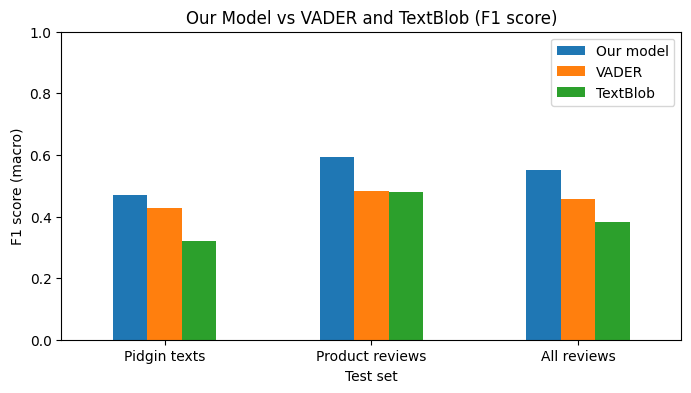

In [57]:
# Let's visualize the comparison
tool_comparison.set_index("Test set").plot(kind="bar", figsize=(8, 4))
plt.title("Our Model vs VADER and TextBlob (F1 score)")
plt.ylabel("F1 score (macro)")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.show()


###Our Model vs VADER and TextBlob
Our model performed better than both VADER and TextBlob on every test set:
1. Product reviews: our model scored 0.593, compared with 0.483 for VADER and 0.480 for TextBlob
2. All reviews: our model scored 0.550, compared with 0.456 for VADER and 0.383 for TextBlob
3. Pidgin texts: our model scored 0.471, clearly ahead of TextBlob (0.319) and slightly ahead of VADER (0.428)

This shows that training on real Nigerian reviews helps the model understand how Nigerians write better than tools built for standard English. Pidgin texts are still the hardest for every model, so this is something we will try to improve.


##Improving the Best Model
Logistic Regression has a setting called C, which controls how closely the model fits the training data:
1. A small C keeps the model simple, so it may miss useful patterns
2. A large C makes it follow the training data very closely, so it may memorise instead of learn

We try several values of C and pick the best using 5-fold cross-validation on the training set only. The training set is split into 5 parts, and the model is trained and checked 5 times, each time on a different part. This way, the testing set stays unseen until the final check.


In [58]:
from sklearn.model_selection import GridSearchCV   # For trying different settings with cross-validation

# The values of C we want to try
param_grid = {"C": [0.1, 0.5, 1, 2, 5, 10]}

# Let's set up the search: it tests each value of C with 5-fold cross-validation,using the macro F1 score (our main score) to decide which is best
grid_search = GridSearchCV(
    LogisticRegression(class_weight="balanced", max_iter=1000, random_state=234),
    param_grid,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

# Let's run the search on the training set only
grid_search.fit(X_train_tfidf, y_train)

# Let's see the result for each value of C
results = pd.DataFrame(grid_search.cv_results_)[["param_C", "mean_test_score"]]
results.columns = ["C", "Average F1 (cross-validation)"]
print(results.round(3))
print()
print("Best value of C:", grid_search.best_params_["C"])


      C  Average F1 (cross-validation)
0   0.1                          0.529
1   0.5                          0.557
2   1.0                          0.559
3   2.0                          0.554
4   5.0                          0.544
5  10.0                          0.534

Best value of C: 1


The best value of C was 1, which is the default our model already uses. So tuning C did not improve the model, but it confirmed that our original setting was already the best.


###Adding Character Pieces
Our current model only reads whole words, so different spellings of the same Pidgin word (e.g. "dey", "de", "dy") look completely different to it. To fix this, we also give the model small pieces of each word (2 to 5 letters long). This helps it recognise words even when they are spelled differently.

We combine the word features and the character features into one, using FeatureUnion.


In [59]:
from sklearn.pipeline import FeatureUnion   # For combining the word features and character features into one

# Let's combine two TF-IDF converters:
# 1. "words": single words and word pairs, the same as before
# 2. "chars": pieces of 2 to 5 letters inside each word, to handle different spellings
improved_tfidf = FeatureUnion([
    ("words", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
    ("chars", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)),
])

# Let's learn from the training set only, then convert both sets
X_train_improved = improved_tfidf.fit_transform(X_train)
X_test_improved = improved_tfidf.transform(X_test)
print("Training set after improved TF-IDF:", X_train_improved.shape)

# Let's train the improved Logistic Regression model (C=1, the best value we found)
improved_model = LogisticRegression(class_weight="balanced", C=1, max_iter=2000, random_state=234)
improved_model.fit(X_train_improved, y_train)

# Let's make predictions on the testing set
improved_pred = improved_model.predict(X_test_improved)
print("Improved model has been trained!")


Training set after improved TF-IDF: (10488, 61858)
Improved model has been trained!


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
 Improved Logistic Regression
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Accuracy: 0.672
F1 score (macro): 0.563

              precision    recall  f1-score   support

    negative       0.72      0.77      0.75      1296
     neutral       0.23      0.32      0.26       215
    positive       0.74      0.62      0.68      1111

    accuracy                           0.67      2622
   macro avg       0.56      0.57      0.56      2622
weighted avg       0.69      0.67      0.68      2622



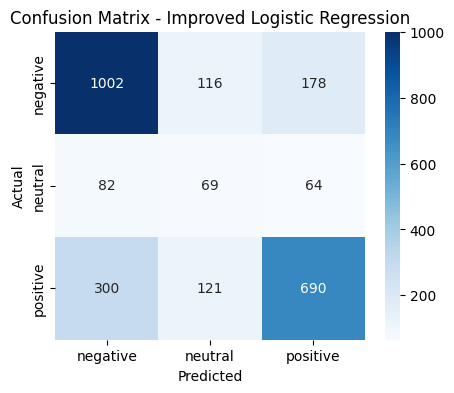

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
 Improved Logistic Regression: results by source
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
jumia      reviews: 389   Accuracy: 0.905   F1 (macro): 0.572
jumia_app  reviews: 226   Accuracy: 0.513   F1 (macro): 0.494
jiji_app   reviews: 276   Accuracy: 0.536   F1 (macro): 0.482
pidgin     reviews: 1731  Accuracy: 0.661   F1 (macro): 0.504

All product reviews F1 (macro): 0.590


In [60]:
# Let's evaluate the improved model on the whole testing set and on each source
improved_accuracy, improved_f1 = evaluate_model("Improved Logistic Regression", y_test, improved_pred)
improved_product_f1 = evaluate_by_source("Improved Logistic Regression", improved_pred)


###Improved Model Results
Adding character pieces improved the model:
1. F1 on all reviews: 0.550 → 0.563, and accuracy 0.659 → 0.672
2. F1 on Pidgin texts: 0.471 → 0.504, now well ahead of VADER (0.428) and TextBlob (0.319)
3. F1 on Jumia reviews: 0.552 → 0.572
4. F1 on all product reviews stayed about the same (0.593 → 0.590)

The biggest gain is on Pidgin, which was our weakest area, so we use this improved model as our final model.


###Testing and Saving the Final Model
Before saving, we test the final model on a few new reviews, written the way Nigerians write. Then we save the model and the TF-IDF converter with joblib, so our Streamlit app can load them and use them without training again.


In [61]:
def predict_review(review):
    """
    A function that cleans a review and predicts its sentiment using the final model
    """
    cleaned = clean_text(review)
    prediction = improved_model.predict(improved_tfidf.transform([cleaned]))[0]
    return label_names[prediction]

# Let's test the final model on a few new reviews
test_reviews = [
    "Na wahala this product, e don spoil",
    "This phone no dey hold charge at all, waste of money",
    "The earpiece sweet well well, I love am",
    "Delivery late reach one week, I vex",
    "Original product, fast delivery, I recommend",
    "E dey okay, nothing special",
]

for review in test_reviews:
    print(f"{predict_review(review):<10} <- {review}")


negative   <- Na wahala this product, e don spoil
negative   <- This phone no dey hold charge at all, waste of money
positive   <- The earpiece sweet well well, I love am
negative   <- Delivery late reach one week, I vex
positive   <- Original product, fast delivery, I recommend
positive   <- E dey okay, nothing special


In [62]:
import joblib   # For saving the model so the app can use it later

# Let's save the final model and the TF-IDF converter
joblib.dump(improved_model, "sentiment_model.pkl")
joblib.dump(improved_tfidf, "tfidf_vectorizer.pkl")

print("Model and TF-IDF converter saved!")


Model and TF-IDF converter saved!


The final model predicted 5 out of the 6 new reviews correctly, including the Pidgin ones. It labelled "E dey okay, nothing special" as positive instead of neutral, which matches our results: neutral is still the hardest class for the model.


##Complaint Detection
Knowing that a review is negative is useful, but sellers also need to know what customers are complaining about. We group complaints into categories using keywords. For example, a negative review that mentions "refund" or "money back" goes under Refund & returns.

A review can belong to more than one category (e.g. a late delivery of a fake product). Reviews that match no keywords go under Other.

We only check negative reviews, because those are the complaints.


In [63]:
 # The complaint categories and the keywords that point to each one (includes Pidgin phrases like "no work" and "spoil")
complaint_keywords = {
    "Delivery": ["deliver", "delivered", "delivery", "late", "delay", "delayed", "shipping",
                 "dispatch", "rider", "waybill", "arrive", "arrived"],
    "Refund & returns": ["refund", "refunded", "return", "returned", "money back"],
    "Fake, wrong or poor quality": ["fake", "original", "counterfeit", "wrong", "not as described",
                                    "overrated", "over rated", "substandard", "quality", "inferior"],
    "Damaged or not working": ["spoil", "spoilt", "working", "stopped", "faulty", "damaged",
                               "broken", "no work", "dead", "issue", "issues", "problem"],
    "Battery & charging": ["battery", "charge", "charging", "charger"],
    "Sound & calls": ["sound", "bass", "volume", "mic", "microphone", "call", "calls",
                      "hear", "audio", "noise"],
    "Connection": ["connect", "connecting", "connected", "connection", "disconnect",
                   "disconnecting", "reconnect", "bluetooth", "pair"],
    "Customer service": ["customer care", "customer service", "support", "agent", "respond", "response"],
    "App & account": ["app", "login", "log in", "account", "install", "update", "password", "otp", "crash"],
    "Payment & orders": ["payment", "pay", "paid", "order", "ordered", "cancel", "cancelled",
                         "debit", "debited", "wallet"],
    "Scam or fraud": ["scam", "fraud", "scammer", "thief", "cheat"],
}

def find_complaints(cleaned_review):
    """
    A function that returns the complaint categories found in a cleaned review
    """
    found = []
    for category, keywords in complaint_keywords.items():
        for word in keywords:
            # \b makes sure we match whole words only (e.g. "pay" will not match "paypal")
            if re.search(r"\b" + re.escape(word) + r"\b", cleaned_review):
                found.append(category)
                break   # one matching keyword is enough for this category If no category matched, we label it as "Other"
    return found if found else ["Other"]


In [64]:
# Let's select only the negative product reviews (Jumia and app reviews)
negative_reviews = df_final[(df_final["sentiment"] == "negative") & (df_final["source"] != "pidgin")].copy()
print("Negative product reviews:", len(negative_reviews))

# Let's find the complaint categories in each review
negative_reviews["complaints"] = negative_reviews["clean_text"].apply(find_complaints)

# Let's count how often each complaint appears (a review can count for more than one)
complaint_counts = negative_reviews["complaints"].explode().value_counts()
complaint_counts


Negative product reviews: 1255


,count
complaints,
Other,419
App & account,417
Payment & orders,241
Delivery,152
Damaged or not working,100
Customer service,96
"Fake, wrong or poor quality",80
Sound & calls,77
Refund & returns,50


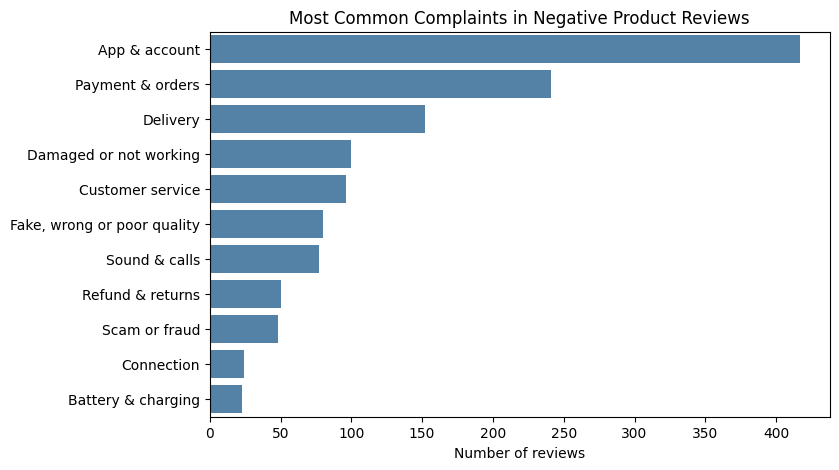

In [65]:
# Let's visualize the most common complaints (we leave out "Other" to focus on clear complaints)
top_complaints = complaint_counts.drop("Other")

plt.figure(figsize=(8, 5))
sns.barplot(x=top_complaints.values, y=top_complaints.index, color="steelblue")
plt.title("Most Common Complaints in Negative Product Reviews")
plt.xlabel("Number of reviews")
plt.ylabel("")
plt.show()


###Complaint Detection Results
Out of 1,255 negative product reviews:
1. The most common complaints are App & account (417), Payment & orders (241) and Delivery (152). This is because most of our negative reviews are about the Jumia and Jiji apps
2. Other complaints include damaged products, customer service, fake or poor quality products, sound, refunds and scams
3. About two out of three complaints matched at least one category. The rest (419) are vague, such as "I don't like it", and are labelled Other


In [66]:
def analyse_review(review):
    """
    A function that predicts the sentiment of a review and,
    if it is negative, finds what the customer is complaining about
    This is the same logic our app will use
    """
    cleaned = clean_text(review)
    sentiment = label_names[improved_model.predict(improved_tfidf.transform([cleaned]))[0]]

    # We only look for complaints in negative reviews
    complaints = find_complaints(cleaned) if sentiment == "negative" else []
    return sentiment, complaints

# Let's test it on a few new reviews
for review in ["Delivery late reach one week, I vex",
               "I paid but my order was cancelled and no refund",
               "This earpiece don spoil after 2 days",
               "Original product, fast delivery, I recommend"]:
    sentiment, complaints = analyse_review(review)
    print(f"{sentiment:<10} {complaints}  <- {review}")


negative   ['Delivery']  <- Delivery late reach one week, I vex
negative   ['Refund & returns', 'Payment & orders']  <- I paid but my order was cancelled and no refund
negative   ['Damaged or not working']  <- This earpiece don spoil after 2 days
positive   []  <- Original product, fast delivery, I recommend


###Testing the Full Analysis
The "analyse_review" function combines our final model and complaint detection. For each review, it predicts the sentiment and if the review is negative, shows what the customer is complaining about. It correctly handled reviews in English and Pidgin, and found multiple complaints in one review (e.g. "Refund & returns" and "Payment & orders"). This is the same logic our Streamlit app will use.
